# Matías Lanas 22.466.806-6

In [5]:
#Helloworld('print')
#importamos las librerias que vamos a ocupar
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


In [ ]:
class CatalogoEstelar:

    '''
    Armamos una clase para gestionar, limpiar, analizar y graficar un catálogo estelar 
    a partir de un archivo .npz que tiene información sobre 100000 estrellas
    '''

    #Definimos las constantes que vamos a usar en os calculos
    sigma_sb = 5.67e-8 #Constante de Stefan-Boltzmann
    radio_solar = 6.96e8 #Radio solar [m]
    luminosidad_solar = 3.828e26 #Luminosidad solar [W]
    temperatura_solar = 5778 #Temperatura solar [K]

    def __init__(self, df_datos):

        '''
        Constructor de la clase CatalogoEstelar. Guarda el Dataframe de datos y los limpia automáticamente

        Parametros:
        ============
        df_datos: DataFrame de pandas
        DataFrame inicial que contiene los datos del catálogo estelar
        '''

        self.df = df_datos.copy()
        self.limpiar_datos()

    @classmethod
    def cargar_npz(cls, ruta_archivo):
        '''
        Metodo de clase para cargar un archivo .npzy almacenarlos en un DataFrame

        Parametros:
        ============
        ruta_archivo: Path
        Ruta hacia el archivo .npz

        Retorna:
        ============
        CatalogoEstelar
        Una nueva instancia de la clase CatalogoEstelar
        '''

        archivo = np.load(ruta_archivo, allow_pickle=True)
        #Extraemos los datos del archivo .npz y los pasamos a un DataFrame
        datos_dict = {
            'nombre': archivo['nombre'],
            'L_Lsol': archivo['L_Lsol'],
            'd_pc': archivo['d_pc'],
            'T_K': archivo['T_K']
        }

        df_cargado = pd.DataFrame(datos_dict)
        return cls(df_cargado)
    @classmethod

    def desde_dataframe(cls, df_input):
        '''
        Metodo alternativo de clase utilizando el decorador @classmethod
        para recibir un DataFrame directamente sin requerir un archivo .npz

        Parametros:
        ============
        df_input: pandas.DataFrame
        DataFrame con las columnas de la muestra

        Retorna:
        ============
        CatalogoEstelar
        Instancia de la clase
        '''

        return cls(df_input)

    def limpiar_datos(self):
        '''
        Encuentra los valores NaN y valores físicos no válidos (negativos o ceros)
        Luego, imprime el reporte con el porcentaje por columna
        '''

        print('=== Reporte de limpieza de datos ===')

        n = len(self.df)

        #Primero los valores NaN
        nulos = self.df.isna().sum()
        porcentaje_nulos = (nulos / n) * 100

        for columna in self.df.columns:
            print(f'- Columna {columna} tiene {nulos[columna]} valores nulos y un porcentaje de {porcentaje_nulos[columna]:.2f}%')

        #Luego filtramos columnas con NaN y valores negativos o ceros
        #Identificamos columnas numericas
        columnas_numericas = [col for col in ['luminosidad', 'distanica', 'temperatura', 'LLsol', 'distancia_pc', 'temperatura_K'] if col in self.df.columns]

        #Eliminamos filas con valores NaN
        self.df = self.df.dropna(subset=columnas_numericas).copy()
        #Usamos el subset para identificar columnas especificas

        #Eliminamos valores fisicos no validos (negativos o ceros)
        for col in columnas_numericas:
            self.df = self.df[self.df[col] > 0].copy()

    def obtener_columnas_normalizadas(self):
        '''
        Este es un metodo auxiliar interno (que se me ocurrio a mi porque soy muy bacan) para estandarizar nombres de columnas independientes
        '''

        df_normalizado = self.df.copy()
        #Creamos un diccionario para mapear nombres de columnas a nombres estandarizados
        mapeo_columnas = {}
        for col in df_normalizado.columns:
            c_low = str(col).lower()
            if 'lum' in c_low or 'l_sol' in c_low or 'llsol' in c_low or 'luminosidad' in c_low:
                mapeo_columnas[col] = 'L_Lsol'
            elif 'dist' in c_low or 'pc' in c_low or 'distanica' in c_low or 'dpc' in c_low:
                mapeo_columnas[col] = 'd_pc'
            elif 'temp' in c_low or 'k' in c_low or 'temperatura' in c_low:
                mapeo_columnas[col] = 'T_K'
            elif 'nom' in c_low or 'id' in c_low or 'estrella' in c_low or 'name' in c_low:
                mapeo_columnas[col] = 'nombre'

        #Una pequeña duda que tengo es si se puede "automatizar" este proceso, ya que hacerlo a mano es bastante ineficiente, por lo menos a mi no se me ocurrio nada mas

        df_normalizado = df_normalizado.rename(columns=mapeo_columnas)
        return df_normalizado

    def calcular_flujo(self):
        '''
        Calcula el flujo de cada estrella usando la ecuación presentada
        F_bol = L / (4 * pi * d^2)
        '''

        df_normalizado = self.obtener_columnas_normalizadas()
        #Si la lumonisdad viene en Lsol, la convertimos a Watts
        #Si viene en Watts se mantiene
        L_watts = df_normalizado['L_Lsol'] * self.luminosidad_solar
        d_metros = df_normalizado['d_pc'] * 3.086e16 #Formula para convertir parsecs a metros

        self.df['Flujo_bol'] = L_watts / (4* np.pi * d_metros**2)
        return self.df['Flujo_bol']


    def calcular_radio(self):
        '''
        Estima el radio usando la ley de Stefan-Boltzmann y la ecuación de la luminosidad
        R / Rsol = sqrt(L / Lsol) * (Tsol / T)^2
        '''

        df_normalizado = self.obtener_columnas_normalizadas()
        L = df_normalizado['L_Lsol']
        T = df_normalizado['T_K']

        self.df['Radio_Rsol'] = np.sqrt(L) * ((self.temperatura_solar / T) ** 2)
        return self.df['Radio_Rsol']

    def calcular_magnitud(self):
        '''
        Calcula la magnitud bolométrica absoluta usando:
        M_bol = 4.74 - 2.5 * log10(L / Lsol)
        '''

        df_normalizado = self.obtener_columnas_normalizadas()
        L = df_normalizado['L_Lsol']

        self.df['Magnitud_bol'] = 4.74 - 2.5 * np.log10(L)
        return self.df['Magnitud_bol']

    def calcular_lambda_max(self):
        '''
        Calcula la longitud de onda de maxima emision mediante el desplazamiento de Wien:
        lambda_max = b / T
        '''

        df_normalizado = self.obtener_columnas_normalizadas()
        b = 2.8978e-3 #Cosntante de Wien en metros Kelvin
        #Resultado convertido en nanometros (1^9)
        self.df['Lambda_max_nm'] = b / df_normalizado['T_K'] * 1e9

        return self.df['Lambda_max_nm']

    def clasificar_deteccion(self, umbral=1e-4):
        '''
        Determina que estrellas son detectables y cuales no, comparando su flujo
        con el umbral especificado (en W m^-2)
        '''

        if 'Flujo_bol' not in self.df.columns:
            self.calcular_flujo()

        condiciones = [
            self.df['Flujo_bol'].isna(),
            self.df['Flujo_bol'] >= umbral,
            self.df['Flujo_bol'] < umbral
        ]

        opciones = ['Desconocida', 'Detectable', 'No detectable']
        self.df['Clasificacion_deteccion'] = np.select(condiciones, opciones, default='Desconocida')
        return self.df['Clasificacion_deteccion']

    def estadisticas(self):
        '''
        Calcula estadisticas descriptivas completas para las propiedades numericas:
        Media, Mediana, Desviacion estandar, Minimo, Maximo, Cuartiles

        Retorna:
        ============
        pandas.DataFrame
        Tabla resumen con las estadisticas
        '''

        #Aseguramos propiedades calculadas
        if 'Flujo_bol' not in self.df.columns: self.calcular_flujo()
        if 'Radio_Rsol' not in self.df.columns: self.calcular_radio()
        if 'Magnitud_bol' not in self.df.columns: self.calcular_magnitud()

        numericas = self.df.select_dtypes(include=[np.number])

        estadisticas = numericas.agg([
            'mean', 'median', 'std',
            lambda x: np.nanpercentile(x, 25), #Primer cuartil
            lambda x: np.nanpercentile(x, 50), #Segundo cuartil
            lambda x: np.nanpercentile(x, 75), #Tercer cuartil
            'min', 'max'
        ])

        estadisticas.index = ['Media', 'Mediana', 'Desviacion estandar', 'Q1', 'Q2', 'Q3', 'Minimo', 'Maximo']

        #Identificamos los extremos de lumonosidad, temperatura y radio
        df_normalizado = self.obtener_columnas_normalizadas()
        print('=== Extremos de la muestra ===')
        print(f'- Luminosidad Maxima: {df_normalizado.loc[df_normalizado['L_Lsol'].idxmax()]['nombre'] if 'nombre' in df_normalizado.columns else 'Desconocido'}')
        print(f'- Luminosidad Minima: {df_normalizado.loc[df_normalizado['L_Lsol'].idxmin()]['nombre'] if 'nombre' in df_normalizado.columns else 'Desconocido'}')
        print(f'- Temperatura Maxima: {df_normalizado.loc[df_normalizado['T_K'].idxmax()]['nombre'] if 'nombre' in df_normalizado.columns else 'Desconocido'}')
        print(f'- Temperatura Minima: {df_normalizado.loc[df_normalizado['T_K'].idxmin()]['nombre'] if 'nombre' in df_normalizado.columns else 'Desconocido'}')
        print(f'- Radio Maximo: {df_normalizado.loc[df_normalizado['Radio_Rsol'].idxmax()]['nombre'] if 'nombre' in df_normalizado.columns else 'Desconocido'}')
        print(f'- Radio Minimo: {df_normalizado.loc[df_normalizado['Radio_Rsol'].idxmin()]['nombre'] if 'nombre' in df_normalizado.columns else 'Desconocido'}')

        return estadisticas

    def resumen_por_temperatura(self, umbral=1e-4):
        '''
        Clasifica las estrellas en tres grupos segun su temperatura: fria, intemrmedia y caliente
        y calcula metricas agregadas usadno pd.cut, groupby y agg
        '''

        df_normalizado = self.obtener_columnas_normalizadas()
        if 'Flujo_bol' not in self.df.columns: self.calcular_flujo()
        if 'Clasificacion_deteccion' not in self.df.columns: self.clasificar_deteccion(umbral)

        bins = [0, 5000, 7500, np.inf]
        labels = ['Fria', 'Intermedia', 'Caliente']
        df_normalizado['Grupo_temp'] = pd.cut(df_normalizado['T_K'], bins=bins, labels=labels)

        resumen = df_normalizado.groupby('Grupo_temp', observed=False).agg(
            Total_de_estrellas = ('T_K', 'count'),
            Temperatura_media = ('T_K', 'min'),
            Luminosidad_media = ('L_Lsol', 'mean'),
            Flujo_mediano = ('Flujo_bol', 'median'),
            Fraccion_detectada = ('Clasificacion_deteccion', lambda x: (x == 'Detectada').sum() / len(x) if len(x) > 0 else 0)
        )

        return resumen

    def graficar_hr(self):
        '''
        Construye el diagrama de Hertzsprung-Rusell (luminosidad vs temperatura efectiva),
        con sus ejes invertidos y en funcion logaritmica
        '''

        df_normalizado = self.obtener_columnas_normalizadas()
        plt.figure(figsize=(10,8))
        plt.scatter(df_normalizado['T_K'], df_normalizado['L_Lsol'], color='blue', alpha=0.8, edgecolors='k')
        plt.yscale('log')
        plt.gca().invert_xaxis() #Invierte el eje de temperatura
        plt.xlabel('Temperatura efectiva $T_{eff}$ [K] (de mayor a menor)')
        plt.ylabel('Luminosidad bolométrica [$L_{\odot}$] (escala logaritmica)')
        plt.title('Diagrama de Hertzsprung-Rusell', fontsize=14)
        plt.grid(True, which='both', ls=':', alpha=0.6)
        plt.tight_layout()
        plt.show()

    def graficar_histogramas(self, bins=15):
        '''
        Construimos los histogramas para las funciones principales
        '''

        df_normalizado = self.obtener_columnas_normalizadas()
        if 'Radio_Rsol' not in self.df.columns: self.calcular_radio()
        if 'Magnitud_bol' not in self.df.columns: self.calcular_magnitud()

        fig, axes = plt.subplots(2, 3, figsize=(15,9))
        axes = axes.ravel()

        props = [
            (df_normalizado['L_Lsol'], 'Luminosidad[$L_{\odot}$]', 'gold'),
            (df_normalizado['d_pc'], 'Distancia [pc]', 'skyblue'),
            (df_normalizado['T_K'], 'Temperatura [K]', 'salmon'),
            (df_normalizado['Radio_Rsol'], 'Radio [$R_{\odot}$]', 'lightgreen'),
            (df_normalizado['Magnitud_bol'], 'Magnitud [$M_{bol}$]', 'grey')
        ]

        for i, (data, xlabel, color) in enumerate(props):
            axes[i].hist(data, bins=bins, color=color, edgecolor='black', alpha=0.8)
            axes[i].set_xlabel(xlabel, fontsize=11)
            axes[i].set_ylabel('Frecuencia', fontsize=11)
            axes[i].grid(True, linestyle='--', alpha=0.5)

        axes[5].axis('off') #Ocultamos el panel que ha sobrado
        plt.suptitle('Distribucion de las propiedades fisicas del catalogo estelar', fontsize=15)
        plt.tight_layout()
        plt.show()

    def graficar_temperatura_flujo(self, umbral=1e-4):
        '''
        Construye una figura de dos paneles:
        - Histograma de temperatura efectiva (izquierda)
        - Gráfico de dispercion (scatter) que representa el flujo en funcion de la distancia (derecha)
        '''

        df_normalizado = self.obtener_columnas_normalizadas()
        if 'Flujo_bol' not in self.df.columns: self.calcular_flujo()

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14,7))

        #Panel de la izquierda: Histograma de temperatura efectiva
        ax1.hist(df_normalizado['T_K'], bins=15, color='orange', edgecolor='black', alpha=0.8)
        ax1.set_xlabel('Temperatura efectiva [K]', fontsize=11)
        ax1.set_ylabel('Numero de estrellas', fontsize=11)
        ax1.set_title('Distribucion de temperaturas', fontsize=13)
        ax1.grid(True, linestyle='--', alpha=0.5)

        #Panel de la derecha: Grafico scatter de flujo vs distancia 
        sc = ax2.scatter(self.df['Flujo_bol'], df_normalizado['d_pc'], c=df_normalizado['T_K'], cmap='inferno', edgecolors='k', alpha=0.9)
        cbar = plt.colorbar(sc, ax=ax2)
        cbar.set_label('Temperatura efectiva [K]', fontsize=11)

        ax2.axhline(umbral, color='red', linestyle='--', linewidth=2, label=f'Umbral ($F_{{lim}}={umbral}$ W m$^{-2}$)')
        ax2.set_yscale('log')
        ax2.set_xlabel('Distancia [pc]', fontsize=11)
        ax2.set_ylabel('Flujo bolométrico [$W m^{-2}$] (log)')
        ax2.set_title('Flujo vs Distancia', fontsize=13)
        ax2.legend(fontsize=10)
        ax2.grid(True, which='both', linestyle='--', alpha=0.5)

        plt.tight_layout()
        plt.show()

    def guardar_resultados(self, ruta_salida='resultados_catalogo_procesado.csv'):
        '''
        Exporta el DataFrame procesado y bien bonito a un archivo .csv
        '''

        self.df.to_csv(ruta_salida, index=False)
        print(f'Resultados guardados exitosamente en {ruta_salida}')



<>:277: SyntaxWarning: invalid escape sequence '\o'
<>:296: SyntaxWarning: invalid escape sequence '\o'
<>:299: SyntaxWarning: invalid escape sequence '\o'
<>:277: SyntaxWarning: invalid escape sequence '\o'
<>:296: SyntaxWarning: invalid escape sequence '\o'
<>:299: SyntaxWarning: invalid escape sequence '\o'
C:\Users\matia\AppData\Local\Temp\ipykernel_9204\4124660302.py:277: SyntaxWarning: invalid escape sequence '\o'
  plt.ylabel('Luminosidad bolométrica [$L_{\odot}$] (escala logaritmica)')
C:\Users\matia\AppData\Local\Temp\ipykernel_9204\4124660302.py:296: SyntaxWarning: invalid escape sequence '\o'
  (df_normalizado['L_Lsol'], 'Luminosidad[$L_{\odot}$]', 'gold'),
C:\Users\matia\AppData\Local\Temp\ipykernel_9204\4124660302.py:299: SyntaxWarning: invalid escape sequence '\o'
  (df_normalizado['Radio_Rsol'], 'Radio [$R_{\odot}$]', 'lightgreen'),


=== Reporte de limpieza de datos ===
- Columna nombre tiene 0 valores nulos y un porcentaje de 0.00%
- Columna LLsol tiene 0 valores nulos y un porcentaje de 0.00%
- Columna d_pc tiene 0 valores nulos y un porcentaje de 0.00%
- Columna temperatura_K tiene 0 valores nulos y un porcentaje de 0.00%
       nombre      LLsol        d_pc  temperatura_K     Flujo_bol  Radio_Rsol
0  Estrella_1  46.689208  206.986833    7867.953200  3.485791e-11    3.685020
1  Estrella_2  16.849681   92.696150    4322.202110  6.272469e-11    7.335687
2  Estrella_3  31.337258   61.859494    6037.528586  2.619501e-10    5.127045
3  Estrella_4  20.548402   78.501743    4442.116343  1.066571e-10    7.669450
4  Estrella_5  23.144053   70.021880    8048.674382  1.509879e-10    2.479283


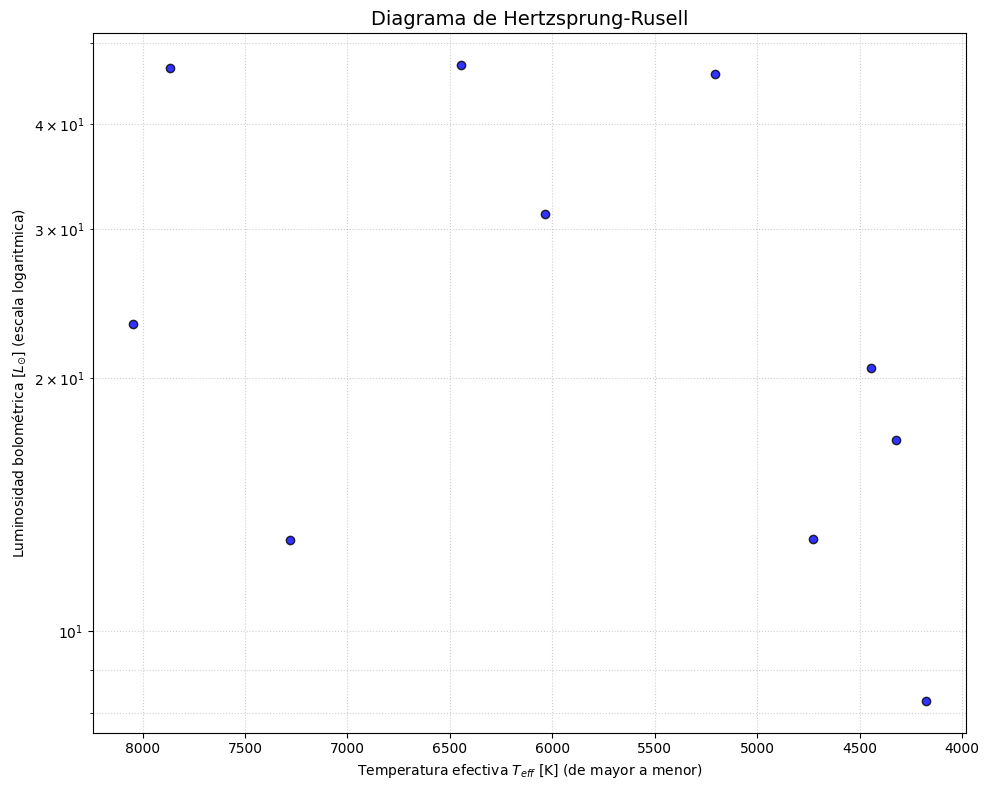

In [18]:
#Luego de toda esta travesia de codigo, lo probamos a ver si funciona 
#1. Construimos manualmente un DataFrame de al menos 10 estrellas
datos_prueba = pd.DataFrame({
    'nombre': [f'Estrella_{i+1}' for i in range(10)],
    'LLsol': np.random.uniform(0.8, 50.0, 10),
    'd_pc': np.random.uniform(60.0, 300.0, 10),
    'temperatura_K': np.random.uniform(3500.0, 9500.0, 10)
})

#2. Instanciamos mediante el metodo de clase alternativo
catalgo_manual = CatalogoEstelar.desde_dataframe(datos_prueba)

#3. Calculamos las propiedades y graficos para comprobar que funciona identico
catalgo_manual.calcular_flujo()
catalgo_manual.calcular_radio()
print(catalgo_manual.df.head())

#4. Probamos grafico
catalgo_manual.graficar_hr()

=== Reporte de limpieza de datos ===
- Columna nombre tiene 0 valores nulos y un porcentaje de 0.00%
- Columna L_Lsol tiene 10015 valores nulos y un porcentaje de 10.02%
- Columna d_pc tiene 10013 valores nulos y un porcentaje de 10.01%
- Columna T_K tiene 9972 valores nulos y un porcentaje de 9.97%
Catalogo .npz cargado correctamente
Numero de estrellas validas tras la limpieza: 100000

Calculando propiedades fisicas

=== Tabla de estadisticas ===
=== Extremos de la muestra ===
- Luminosidad Maxima: Estrella_45903
- Luminosidad Minima: Estrella_21478
- Temperatura Maxima: Estrella_70445
- Temperatura Minima: Estrella_36023
- Radio Maximo: Estrella_2395
- Radio Minimo: Estrella_62716


C:\Users\matia\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in sqrt
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\matia\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


,L_Lsol,d_pc,T_K,Flujo_bol,Radio_Rsol,Magnitud_bol,Lambda_max_nm
Media,44.598852,243.831197,5779.498307,5.624822e-11,7.418687,0.816928,441.869334
Mediana,47.329978,260.891301,6302.173629,1.728299e-11,5.074254,0.486900,431.283567
Desviacion estandar,36.788731,181.536205,3601.386405,1.286306e-10,6.360328,1.061642,289.809339
Q1,20.864351,142.317142,4444.436628,7.166635e-12,3.130467,0.051893,338.424727
Q2,47.329978,260.891301,6302.173629,1.728299e-11,5.074254,0.486900,431.283567
Q3,73.604458,380.223195,8154.575853,4.997317e-11,9.608668,1.238316,596.223558
Minimo,-99.998251,-499.973635,-9992.366755,-1.098191e-09,0.113146,-0.259993,-965.875764
Maximo,99.999374,499.999038,9999.904282,1.268139e-09,36.868159,7.225810,965.893826



=== Resumen por grupo de temperatura ===


,Total_de_estrellas,Temperatura_media,Luminosidad_media,Flujo_mediano,Fraccion_detectada
Grupo_temp,,,,,
Fria,24139,3000.122706,44.382188,1.741732e-11,0.0
Intermedia,30397,5000.134908,44.638170,1.739516e-11,0.0
Caliente,30458,7500.079302,44.502219,1.707429e-11,0.0



=== Graficos ===


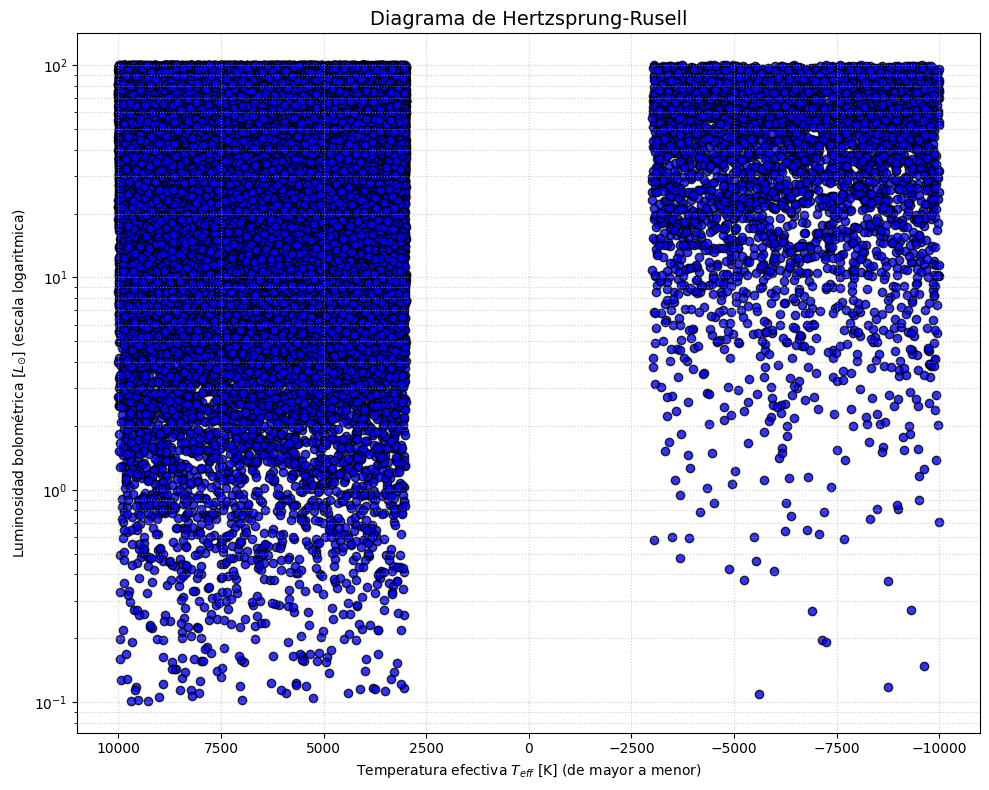

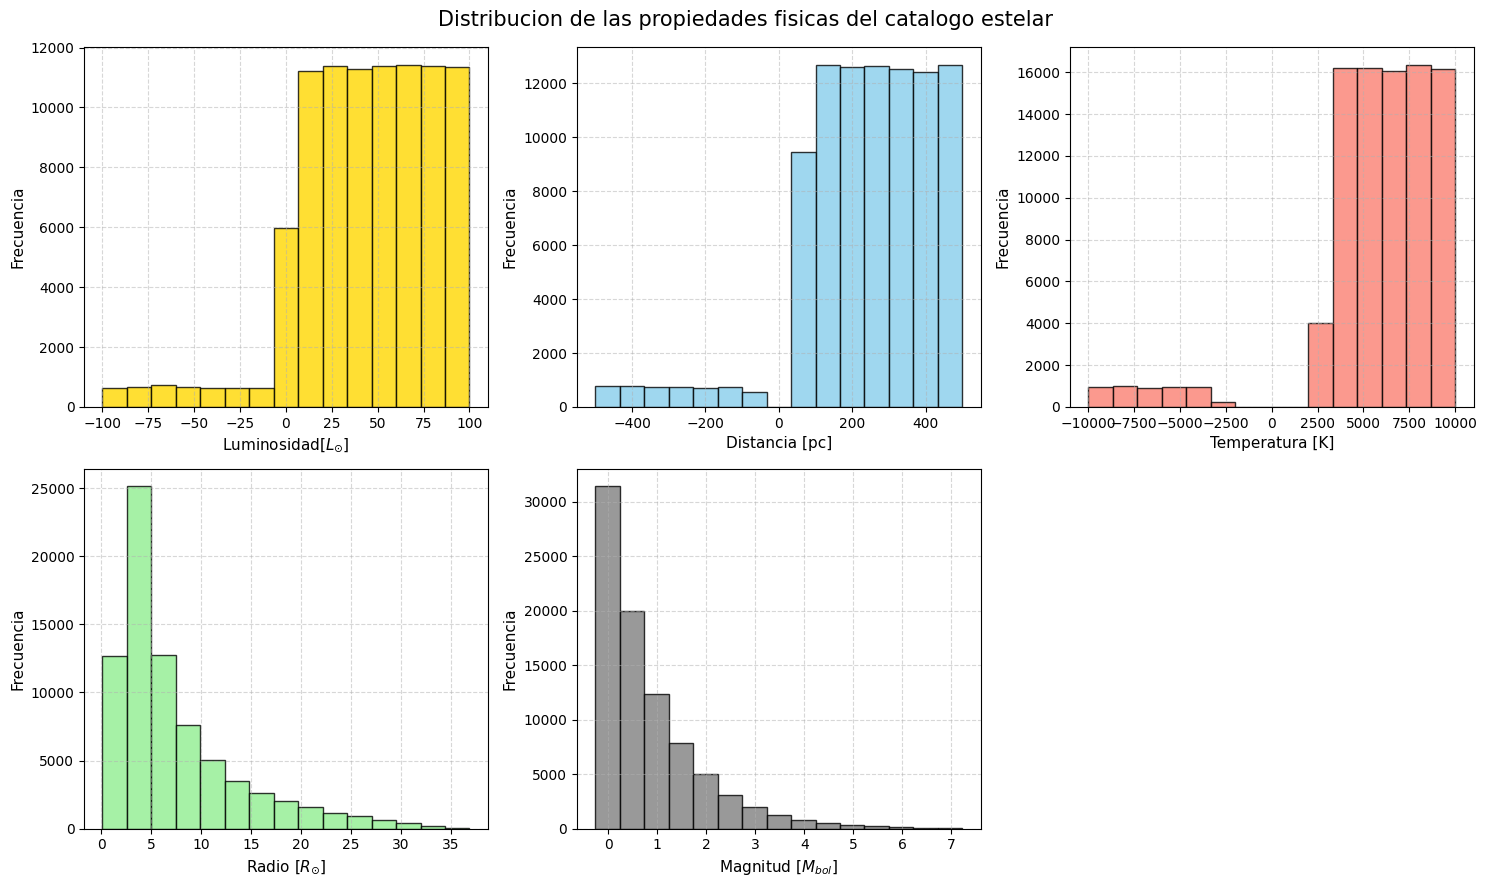

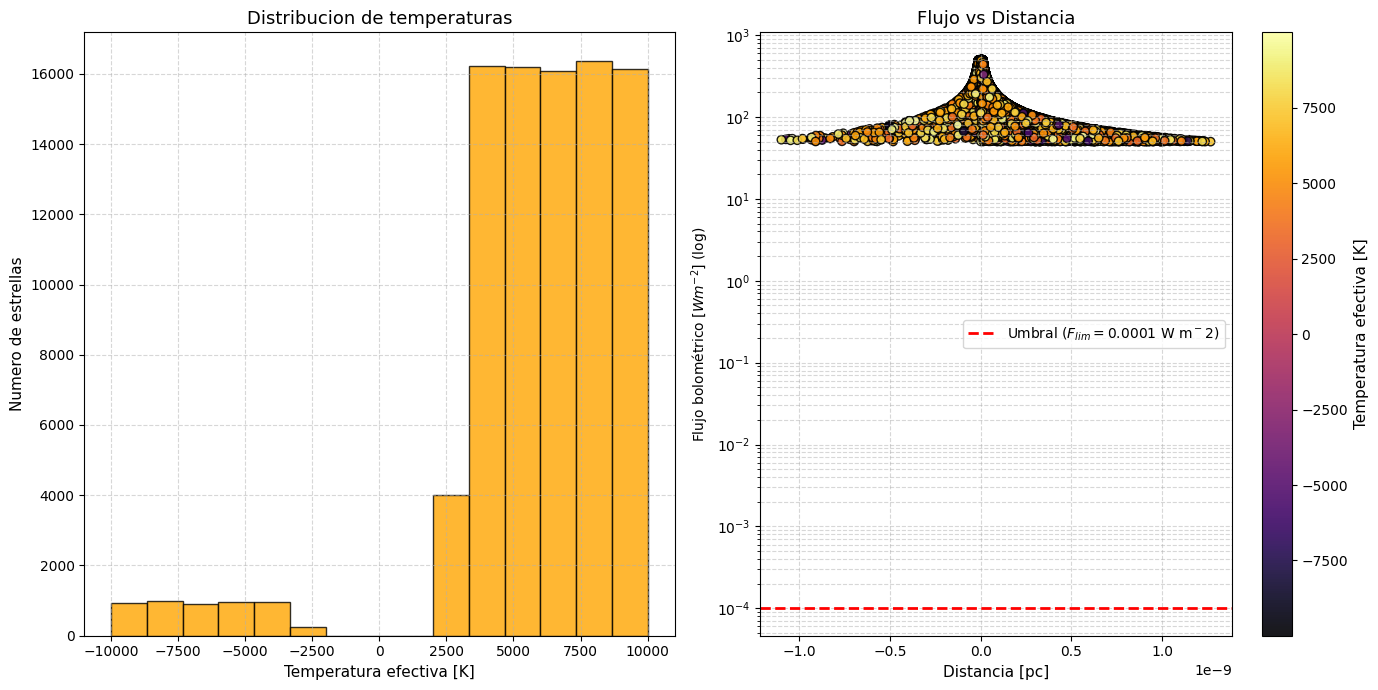

Resultados guardados exitosamente en resultados_catalogo_100000_estrellas_procesado.csv


In [47]:
#Ahora que sabemos que funciona, llego la hora de probar todo nuestro codigo
#Mi parte favorita

#1. Cargamos el catalogo desde el archivo .npz utilizando el metodo de clase
archivo_npz_path = 'catalogo_100000_estrellas.npz'
catalogo_real = CatalogoEstelar.cargar_npz(archivo_npz_path)

print('Catalogo .npz cargado correctamente')
print(f'Numero de estrellas validas tras la limpieza: {len(catalogo_real.df)}\n')

#2. Calculamos todas las propiedades fisicas
print('Calculando propiedades fisicas')
catalogo_real.calcular_flujo()
catalogo_real.calcular_radio()
catalogo_real.calcular_magnitud()
catalogo_real.calcular_lambda_max()

#3. Clasificamos la deteccion usando el umbral predeterminado
catalogo_real.clasificar_deteccion(umbral=1e-4)

#4. Luego, mostramos la tabla de estadisticas completa e identificamos los extremos
print('\n=== Tabla de estadisticas ===')
tabla_de_estadisticas = catalogo_real.estadisticas()
display(tabla_de_estadisticas) #display() es para que la tabla se vea bonita

#5. Generamos el resumen agrupado por temperatura
print('\n=== Resumen por grupo de temperatura ===')
resumen_temp = catalogo_real.resumen_por_temperatura(umbral=1e-4)
display(resumen_temp)

#6. Ejecutamos todas las visualizaciones graficas solicitadas
print('\n=== Graficos ===')
catalogo_real.graficar_hr()
catalogo_real.graficar_histogramas(bins=15)
catalogo_real.graficar_temperatura_flujo(umbral=1e-4)

#7. Exportamos los resultados procesados a un archivo .csv
catalogo_real.guardar_resultados('resultados_catalogo_100000_estrellas_procesado.csv')